# Course Name: Marketing Analytics
## Course Code: DS 4115
### Lab Manual 2: Exploratory Data Analysis (EDA) & Digital Conversion Funnel Analysis using Python

### Set Up Your Python Environment
Run the following code block to import the required data science libraries:

In [12]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization styles
sns.set_theme(style="whitegrid")
print("Environment successfully set up!")

Environment successfully set up!


### Part 1: Generating and Loading Digital Session Logs
#### Step 1: Generate Synthetic GA4 Session Logs
Copy and run the script below to generate 5,000 realistic digital session logs featuring user IDs, device categories, funnel progression flags, page views, and time spent on site:

In [13]:
# Set random seed for reproducibility
np.random.seed(42)
n_rows = 5000

# Generate dummy session attributes
session_ids = [f"sess_{i:04d}" for i in range(1, n_rows + 1)]
user_ids = [f"user_{np.random.randint(1000, 2000)}" for _ in range(n_rows)]
device_categories = np.random.choice(['desktop', 'mobile', 'tablet'], size=n_rows, p=[0.5, 0.4, 0.1])

# Funnel flags (session_start is always 1, others follow realistic probabilities)
session_start_flag = np.ones(n_rows, dtype=int)
add_to_cart_flag = np.random.choice([0, 1], size=n_rows, p=[0.7, 0.3]) # 30% add to cart
purchase_flag = np.where(add_to_cart_flag == 1, np.random.choice([0, 1], size=n_rows, p=[0.4, 0.6]), 0) # 60% conversion from cart

page_views = np.random.poisson(lam=3, size=n_rows) + 1
time_on_site_sec = page_views * np.random.randint(20, 60, size=n_rows)

# Create DataFrame
df = pd.DataFrame({
    'session_id': session_ids,
    'user_id': user_ids,
    'device_category': device_categories,
    'session_start_flag': session_start_flag,
    'add_to_cart_flag': add_to_cart_flag,
    'purchase_flag': purchase_flag,
    'page_views': page_views,
    'time_on_site_sec': time_on_site_sec
})

# Introduce artificial missing values in 'time_on_site_sec' for data cleaning practice
df.loc[np.random.choice(n_rows, 50), 'time_on_site_sec'] = np.nan

# Save to CSV and inspect the first 5 rows
df.to_csv('ga4_sample_session_logs.csv', index=False)
print("Dataset 'ga4_sample_session_logs.csv' successfully generated and loaded!")
display(df.head())

Dataset 'ga4_sample_session_logs.csv' successfully generated and loaded!


,session_id,user_id,device_category,session_start_flag,add_to_cart_flag,purchase_flag,page_views,time_on_site_sec
0,sess_0001,user_1102,tablet,1,0,0,5,155.0
1,sess_0002,user_1435,desktop,1,0,0,3,171.0
2,sess_0003,user_1860,tablet,1,0,0,2,110.0
3,sess_0004,user_1270,desktop,1,0,0,4,140.0
4,sess_0005,user_1106,desktop,1,1,0,4,80.0


#### Step 2: Inspect Dataset Structure
Run the following code to check column data types and non-null counts:

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   session_id          5000 non-null   object 
 1   user_id             5000 non-null   object 
 2   device_category     5000 non-null   object 
 3   session_start_flag  5000 non-null   int64  
 4   add_to_cart_flag    5000 non-null   int64  
 5   purchase_flag       5000 non-null   int64  
 6   page_views          5000 non-null   int64  
 7   time_on_site_sec    4950 non-null   float64
dtypes: float64(1), int64(4), object(3)
memory usage: 312.6+ KB


### Part 2: Constructing the Digital Conversion Funnel
#### Step 1: Calculate Funnel Step Volumes
A conversion funnel tracks user progression through key milestones (session_start → add_to_cart → purchase). Run the script below to compute absolute user sessions and conversion rates relative to Step 1:

In [15]:
# Calculate funnel metrics
total_sessions = df['session_id'].nunique()
sessions_with_cart = df[df['add_to_cart_flag'] == 1]['session_id'].nunique()
sessions_with_purchase = df[df['purchase_flag'] == 1]['session_id'].nunique()

# Create a summary DataFrame
funnel_data = {
    'Funnel Step': ['1. Session Start', '2. Add to Cart', '3. Purchase'],
    'User Sessions': [total_sessions, sessions_with_cart, sessions_with_purchase]
}
funnel_df = pd.DataFrame(funnel_data)

# Calculate conversion rates relative to step 1
funnel_df['Conversion Rate (%)'] = (funnel_df['User Sessions'] / total_sessions) * 100
display(funnel_df)

,Funnel Step,User Sessions,Conversion Rate (%)
0,1. Session Start,5000,100.0
1,2. Add to Cart,1470,29.4
2,3. Purchase,905,18.1


### Part 3: Data Cleaning & Handling Missing Values
Real-world telemetry data is often messy, containing missing or corrupt records.
#### Step 1: Detect Missing Values
Check where missing data resides across columns:

In [16]:
print(df.isnull().sum())

session_id             0
user_id                0
device_category        0
session_start_flag     0
add_to_cart_flag       0
purchase_flag          0
page_views             0
time_on_site_sec      50
dtype: int64


#### Step 2: Impute and Clean Data
Apply median imputation for numeric anomalies and clean string whitespace:

In [17]:
# Impute missing time_on_site_sec with median
median_time = df['time_on_site_sec'].median()
df['time_on_site_sec'] = df['time_on_site_sec'].fillna(median_time)

# Drop rows with missing session IDs if any
df = df.dropna(subset=['session_id'])

# Clean categorical formatting
df['device_category'] = df['device_category'].str.lower().str.strip()
print("Data cleaning completed. Missing values remaining:", df.isnull().sum().sum())

Data cleaning completed. Missing values remaining: 0


### Part 4: Exploratory Data Analysis & Correlation Heatmap
To isolate digital conversion blockers (e.g., identifying why users abandon sessions or fail to purchase), we will calculate statistical correlations across user engagement variables.
#### Step 1: Generate Correlation Matrix

In [18]:
# Remove constant column
numeric_cols = [
    'add_to_cart_flag',
    'purchase_flag',
    'page_views',
    'time_on_site_sec'
]

corr_matrix = df[numeric_cols].corr()
display(corr_matrix)

,add_to_cart_flag,purchase_flag,page_views,time_on_site_sec
add_to_cart_flag,1.000000,0.728494,-0.010963,0.001849
purchase_flag,0.728494,1.000000,-0.000583,0.004230
page_views,-0.010963,-0.000583,1.000000,0.804072
time_on_site_sec,0.001849,0.004230,0.804072,1.000000


#### Step 2: Plot the Heatmap
Visualize the correlation matrix using seaborn:

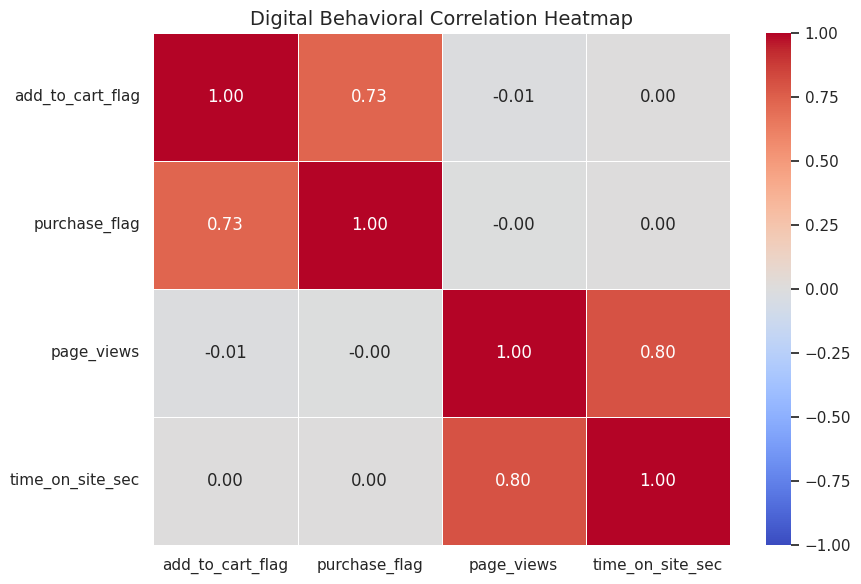

In [19]:
# Plot the correlation heatmap
plt.figure(figsize=(9, 6))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    center=0
)

plt.title(
    "Digital Behavioral Correlation Heatmap",
    fontsize=14
)

plt.tight_layout()
plt.show()

Funnel insights

In [20]:

cart_conversion = (
    sessions_with_purchase / sessions_with_cart
) * 100

cart_abandonment = 100 - cart_conversion

print(f"Cart-to-Purchase Rate: {cart_conversion:.2f}%")
print(f"Cart Abandonment Rate: {cart_abandonment:.2f}%")


Cart-to-Purchase Rate: 61.56%
Cart Abandonment Rate: 38.44%


Save cleaned dataset

In [21]:
df.to_csv('ga4_cleaned_session_logs.csv', index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


## Conclusion

In this lab, Exploratory Data Analysis (EDA) and Digital Conversion Funnel Analysis were performed using Python.

A synthetic dataset containing 5,000 digital sessions was generated to simulate e-commerce user behavior. The conversion funnel analysis showed that 29.4% of sessions resulted in adding products to the cart, while 18.1% resulted in purchases.

Data cleaning was performed using median imputation to handle 50 missing values in the `time_on_site_sec` column. Categorical data was also standardized using pandas.

The correlation analysis revealed a strong positive relationship between add-to-cart and purchase behavior (0.728). Page views and time spent on the website also showed a strong positive correlation (0.804), while their individual correlations with purchase were nearly zero.

Overall, this lab demonstrated how Python-based data analysis can help understand customer behavior, identify conversion funnel drop-offs, and support data-driven marketing decisions. Since the dataset is synthetic, these findings should be interpreted as simulated patterns rather than real-world causal relationships.